# 08 · Hybrid models (Step 5)

**Why a hybrid.** Phase 1 showed that a regularised LogReg on the 43 hand-built features is hard to beat. The brief's hypothesis is that manual summaries miss interactions between time, airport, carrier and recent delay dynamics. The hybrid tests exactly that: keep the ML model, and let a network learn only what it misses.

* **Wide & Deep (main).** logit = LogReg part (wide: the Phase 1 LogReg design matrix) + deep part (embeddings, numerics and, if it won Step 4, the GRU history encoder). The wide part is initialised from the LogReg fitted on the same fold's rows and trained jointly; the deep part's output layer starts at zero, so the untrained hybrid **is** the Phase 1 LogReg (tested in `tests/test_train.py`). Joint training avoids the stacking leak of a frozen in-sample offset.
* **Embeddings → XGBoost (secondary).** The MLP's carrier, origin and destination embeddings added as features to the Phase 1 XGBoost configuration. Only low-cardinality embeddings are transferred: a rare tail number's embedding would memorise its labels.
* **Search:** 12 configurations of learning rate, weight decay and the wide part's learning-rate scale; best re-scored with 5 seeds.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().resolve().parent
for p in (ROOT / 'src', ROOT.parent / 'phase1' / 'src'):
    sys.path.insert(0, str(p))

import aerocast_dl  # torch before XGBoost (OpenMP)
import numpy as np, pandas as pd
from IPython.display import Image, display
from aerocast_dl import config, pipeline
R, F = config.RESULTS_DIR, config.FIGURES_DIR
pd.set_option('display.precision', 4)


## 1. Search

In [2]:
search = pd.read_csv(R / 'search_wide_deep.csv').sort_values('cv_pr_auc', ascending=False)
spec = pipeline.load_spec('wide_deep')
print('deep part:', 'MLP + GRU' if spec.seq_names else 'MLP', '| wide part: Phase 1 LogReg (C = 0.1)')
search

deep part: MLP + GRU | wide part: Phase 1 LogReg (C = 0.1)


,config,lr,weight_decay,wide_lr_scale,cv_pr_auc,fold_m5,fold_m6,fold_m7,fold_m8,mean_best_epoch
0,0,0.0003,1.0000e-05,0.1,0.4707,0.4347,0.5002,0.5551,0.3925,1.00
2,2,0.0003,1.0000e-04,0.1,0.4706,0.4348,0.5002,0.5551,0.3925,1.00
3,3,0.0003,1.0000e-04,1.0,0.4694,0.4347,0.5011,0.5560,0.3857,1.25
1,1,0.0003,1.0000e-05,1.0,0.4693,0.4347,0.5011,0.5560,0.3855,1.25
4,4,0.0010,1.0000e-05,0.1,0.4678,0.4385,0.4878,0.5584,0.3866,1.00
6,6,0.0010,1.0000e-04,0.1,0.4678,0.4382,0.4877,0.5594,0.3858,1.00
7,7,0.0010,1.0000e-04,1.0,0.4664,0.4381,0.4841,0.5568,0.3865,1.00
5,5,0.0010,1.0000e-05,1.0,0.4662,0.4378,0.4829,0.5577,0.3866,1.00
8,8,0.0030,1.0000e-05,0.1,0.4661,0.4354,0.4852,0.5543,0.3896,1.00
10,10,0.0030,1.0000e-04,0.1,0.4658,0.4357,0.4830,0.5548,0.3898,1.00


## 2. Does the hybrid add value over LogReg?

Paired by fold, against the model it starts from. A gain inside the seed SD, or in only two of four folds, is not evidence of value.

In [3]:
cv = pd.concat([pipeline.phase1_cv(), pd.read_csv(R / 'cv_models.csv')], ignore_index=True)
cv = cv[~cv['model'].str.startswith('ablation:')].set_index('model')
lr = cv.loc['Phase 1 LogReg', pipeline.FOLD_COLS].astype(float)
rows = ['Phase 1 LogReg', 'Phase 1 XGBoost', 'mlp', 'gru', 'wide_deep', 'emb_xgb']
for m in ['wide_deep', 'emb_xgb']:
    d = cv.loc[m, pipeline.FOLD_COLS].astype(float) - lr
    print(f'{m} - LogReg per fold: {np.round(d.to_numpy(), 4)} | mean {d.mean():+.4f} | better in {(d > 0).sum()}/4 folds')
cv.loc[rows, ['cv_pr_auc_mean', 'cv_pr_auc_std', *pipeline.FOLD_COLS, 'seed_sd_mean_over_folds', 'n_params']]

wide_deep - LogReg per fold: [ 0.001  -0.0047  0.0012 -0.0068] | mean -0.0023 | better in 2/4 folds
emb_xgb - LogReg per fold: [-0.0152 -0.067  -0.0031  0.0016] | mean -0.0209 | better in 1/4 folds


,cv_pr_auc_mean,cv_pr_auc_std,fold_m5,fold_m6,fold_m7,fold_m8,seed_sd_mean_over_folds,n_params
model,,,,,,,,
Phase 1 LogReg,0.4714,0.0711,0.4343,0.5052,0.5525,0.3936,NaN,NaN
Phase 1 XGBoost,0.4500,0.0671,0.4315,0.4253,0.5479,0.3953,NaN,NaN
mlp,0.4655,0.0755,0.4317,0.5041,0.5481,0.3781,0.0035,27501.0
gru,0.4672,0.0749,0.4342,0.5033,0.5504,0.3807,0.0051,37101.0
wide_deep,0.4691,0.0731,0.4353,0.5006,0.5537,0.3869,0.0036,37255.0
emb_xgb,0.4505,0.0682,0.4191,0.4382,0.5494,0.3952,0.0018,NaN


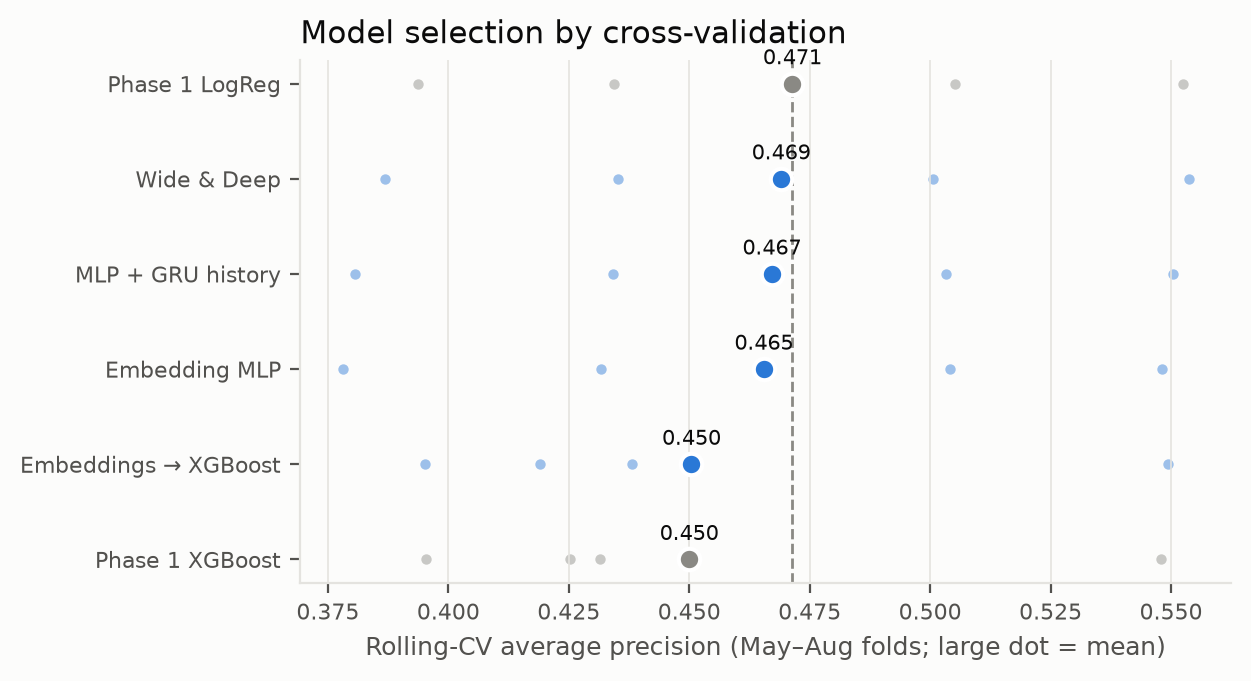

In [4]:
display(Image(F / 'cv_models.png', width=700))